Compare active and idle states of IOT devices

Code structure: if possible have data and display independent, so that time can be saved by not recomputing unchanged data

e.g 
```python
show_data(get_data())
```

rather than
```python
def show_data():
    get_data()
```

also increases configurability

Terms:
* Class
* Window (w seconds long)
* Shift (s seconds)

In [2]:
THIRTY_MINUTES = 1750 # approx number of samples in 30 minutes

from enum import Enum
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
import pandas as pd
import numpy as np
from pandas.plotting import table 
import os
from colorhash import ColorHash
from functools import reduce
from collections import Counter

import matplotlib.style as mplstyle
mplstyle.use('fast')

class State(Enum):
    ACTIVE = "active"
    IDLE = "idle"

BASE_PATH = '../PowerIDS/classifier/power_csv'
# TODO make this a function / context? or cache to a file?
# TODO clean up echodot3
categories = os.listdir(f'{BASE_PATH}')
devices = {dir: [dev for dev in os.listdir(f'{BASE_PATH}/{dir}') if dev != 'echodot3'] for dir in categories} 
devices_to_cat = {d: category for category, ds in devices.items() for d in ds}
devices_flat = [x for xs in devices.values() for x in xs]
num_devices = len(devices_flat)
print(devices)
def get_data(mode, include=[], exclude=[]): 
    devices = devices_flat  
    if len(include) > 0:
        devices = include
    split = THIRTY_MINUTES
    splitter = lambda data: (
        data.iloc[:split, :],
        data.iloc[split:, :]
    )
    return {device: splitter(get_dataframe(device, mode)) for device in devices if device not in exclude}

# look at time
def get_dataframe(device, state: State):
    data = pd.read_csv(f'{BASE_PATH}/{devices_to_cat[device]}/{device}/{state}.csv', parse_dates=["timestamp"])
    if (device == "echodot3" and state == "idle"):
        # data is super short
        return None
    elif (device == "nestmini2"):
        data['power_mW'] = data['power_W']
    return data
    
def plot(device, state: State, ax, function):
    df = get_dataframe(device, state)
    # every tenth value to speedup
    df['time'] = np.linspace(0, 50, len(df))
    time = function(df['time'])
    
    power = function(df['power_mW']) / 1000

    ax.plot(time, power)
    return power.max()

# def evaluate
def sort_dict_by_value(dict, key=lambda x: x[1], reverse=False):
    return {k: v for k, v in sorted(dict.items(), key=key, reverse=reverse)}

def window(df, samples, offset):
    return df.iloc[offset: offset + samples]

def intervalise(metric):
    return pd.Interval(min(metric), max(metric))

def compute_profile(df, s, o):
    """
    run all windows, return metrics in the form {'metric': [value]}, where the values are sorted 

    the first window takes up s samples, so there are len(data) - s samples left. each addional window uses up o spaces.

>>> len(profile(pd.DataFrame(data={'power_mW': [1] * 100}), 10, 2)['mean'])
46

    Additonal partial windows aren't counted
>>> len(profile(pd.DataFrame(data={'power_mW': [1] * 101}), 10, 2)['mean'])
46

  Non overlapping windows
>>> len(profile(pd.DataFrame(data={'power_mW': [1] * 100}), 10, 20)['mean'])
5

>>> len(profile(pd.DataFrame(data={'power_mW': [1] * 1750}), 400, 10)['mean'])
136
   """
    means = []
    stds = []

    # TODO do we want non rectangular windows? are edge effects important

    for bin in range((len(df) - s) // o + 1):
        window_power = window(df, s, o * bin).power_mW
        means.append(window_power.mean())
        stds.append(window_power.std())

    return {'mean': sorted(means), 'std': sorted(stds)}





{'camera': ['google1d15', 'hualai', 'amcrest266e', 'bluram6da9', 'yibefb', 'boifun80c0'], 'audio': ['homepod', 'bose', 'googlehome', 'echodot5', 'echospot', 'sonos', 'nestmini2'], 'appliance': ['weekett', 'xiaomiblender', 'levoit', 'honeywell', 'cosori', 'swan'], 'lights': ['yeelight4', 'lepro', 'tapo', 'lifx', 'antela', 'wiz', 'fitop'], 'tv': ['samsungtv', 'LGtv', 'samsungtvsmall', 'toshiba', 'tcltv', 'appletv']}


AttributeError: 'tuple' object has no attribute 'power_mW'

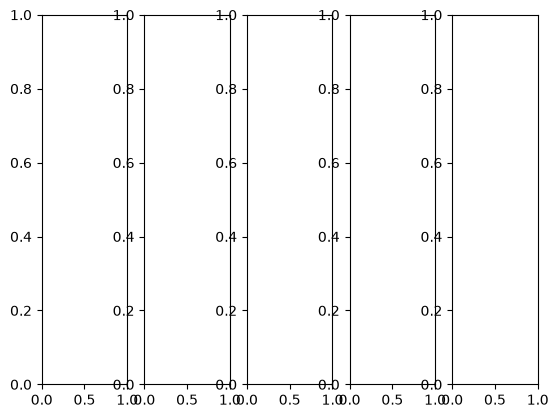

In [3]:
#| label: plot1
times = []
means = []
stds = []
samples = []
fig,ax = plt.subplots(1,5)

categories_labels = []
for i, (device, df) in enumerate(get_data("idle").items()):
    category = devices_to_cat[device]
    if category in categories_labels:
        category_label = f'_{category}'
    else:
        category_label = category
    categories_labels.append(category)
    colour = ColorHash(devices_to_cat[device]).hex

    mean = df.power_mW.mean()
    std = df.power_mW.std()
    times.append(df.timestamp.iat[-1] - df.timestamp[0])
    means.append(mean)
    stds.append(std)
    samples.append(len(df))
   
    ax[categories.index(category)].errorbar(device, mean, std, linestyle='none', markersize=15, markerfacecolor=colour, markeredgecolor='none', marker=".", label=category_label)


width = 15
ratio = 0.2
fig.set_figwidth(width)
fig.set_figheight(width * ratio)


means = np.array(means)
stds = np.array(stds)
for i in range(5):
    ax[i].tick_params('x', rotation=90)
    ax[i].legend()
plt.show()

def my_style(styler):
    styler.format(lambda v: f'{v.total_seconds() / 60:.0f} m {v.total_seconds() % 60:.0f} s', 'minutes')
    styler.format(lambda v: f'{v:.0f} mW', subset='means')
    styler.format(lambda v: f'{v:.0f}', subset='std')
    styler.format(lambda v: f'{v * 100:.0f}%', subset='cv')
    styler.relabel_index(["Minutes", "samples", "μ", "σ", "CV"], axis="columns")
    return styler

results = pd.DataFrame(index=devices_flat, data={ "minutes": times, 'samples': samples, 'means': means, 'std': stds, 'cv': stds/means})
results.style.pipe(my_style)



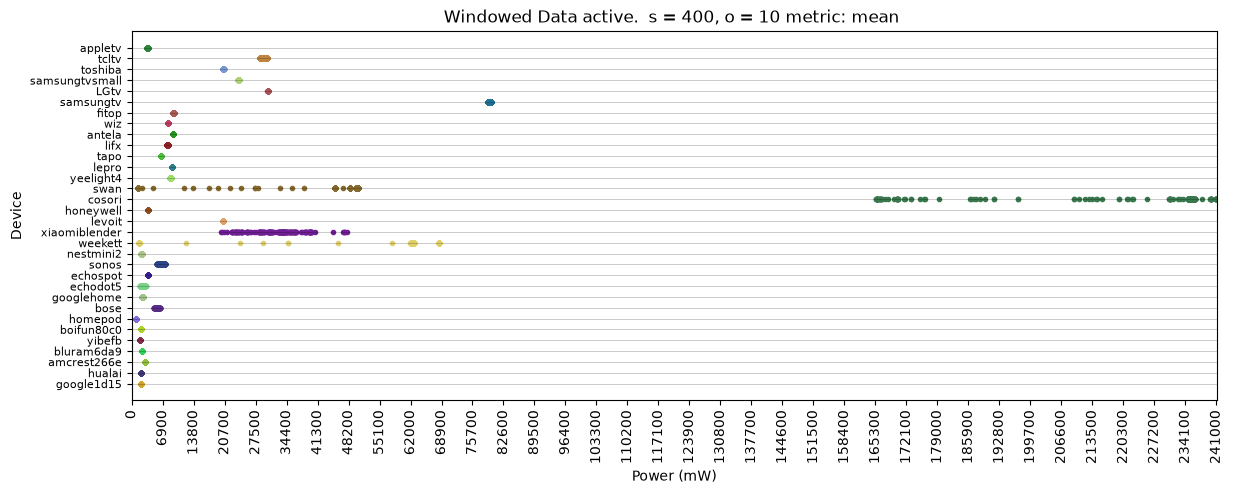

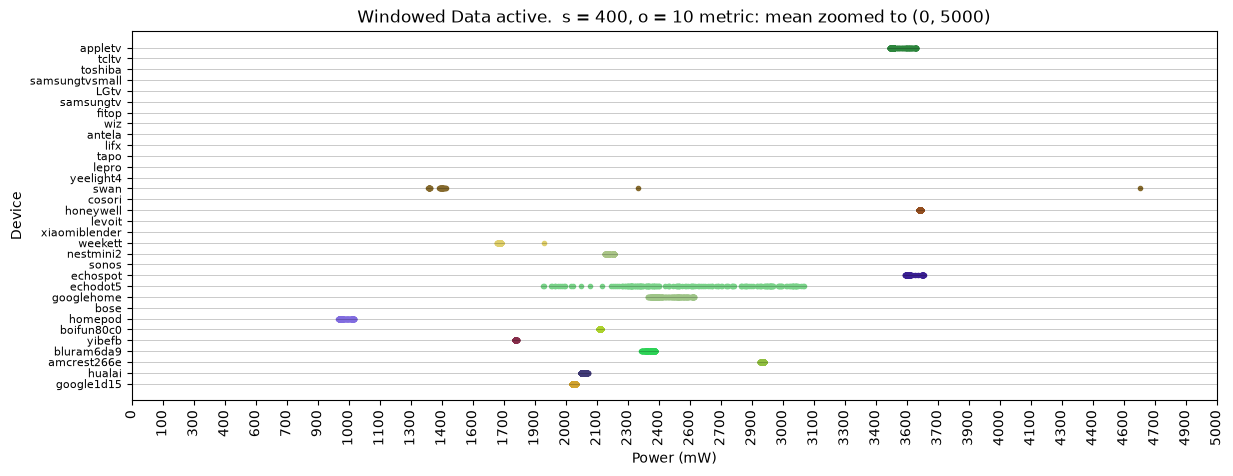

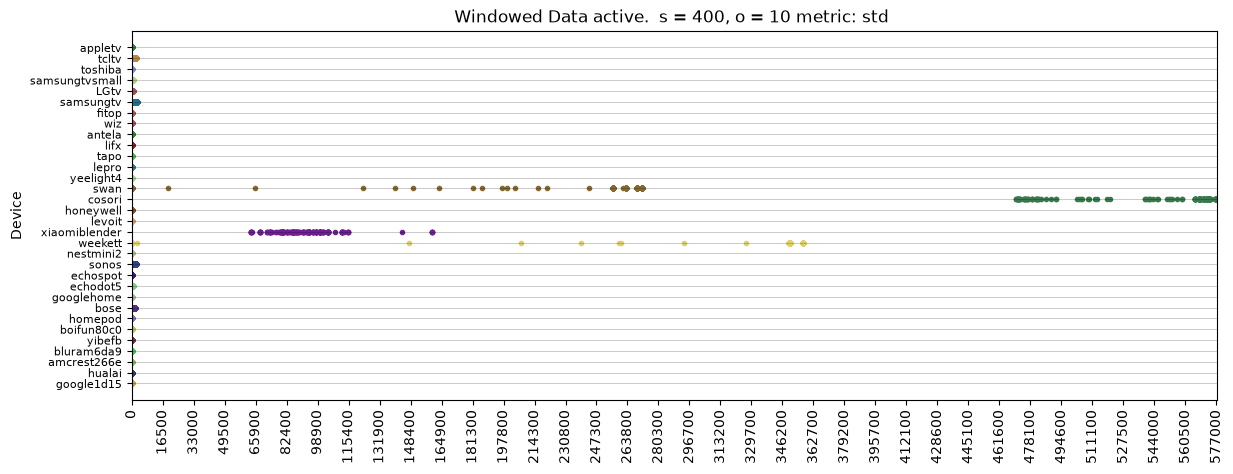

In [ ]:
# | label: profiles

def graph_profiles(mode, samples, offset, metric='mean', zoom=None):
    # get the profiles for the metric, sorted size of spread
    data = get_data(mode)
    results = {device: compute_profile(df, samples, offset)[
        metric] for device, df in data.items()}
    # print(results)

    fig_numberline, numberline = plt.subplots(1, 1)
    numberline.set_title(
        f"Windowed Data {mode}.  s = {samples}, o = {offset} metric: {metric} {'zoomed to ' + str(zoom) if zoom else ''}")

    points = []

    # get the highest value so we know the xlim
    if not zoom:
        xlim = (0, max(results.values(), key=lambda x: x[-1])[-1])
    else:
        xlim = zoom
    for height, (device, result) in enumerate(results.items()):
        dev_colour = ColorHash(device).hex

        # do all the plotting manually, using annotate and scatter
        points.append(numberline.scatter(
            result, [height] * len(result), c=dev_colour, marker="."))

    numberline.tick_params('x', rotation=90)

    numberline.set_xticks(np.linspace(0, round(xlim[1], -3), 36))
    numberline.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, pos: f"{int(round(v, -2))}"))

    numberline.set_yticks(range(num_devices), labels=devices_flat)
    numberline.tick_params(axis='y', which='major', labelsize=8)
    numberline.set_ylabel("Device")
    if metric == 'mean':
        numberline.set_xlabel("Power (mW)")

    numberline.grid(axis='y', color="#0000004B", linestyle='-', linewidth=0.5)
    # fig_numberline.set_figheight(1)
    fig_numberline.set_figwidth(14)

    numberline.set_xlim(xlim)

    # fig_numberline.draw_without_rendering()
    # for point in points:
    #     bbox = point.get_tightbbox()
    #     box = patches.Rectangle(
    #         (bbox.x0, bbox.y0), bbox.x1 - bbox.x0, bbox.y1 - bbox.y0)
    #     box.set_color("black")
    #     box.set_fill(True)
    #     numberline.add_patch(box)
 
    # TODO readd legend


# exclude=['cosori', 'samsungtv', 'xiaomiblender', 'swan']
graph_profiles("active", 400, 10)
graph_profiles("active", 400, 10, zoom=(0, 5000))
graph_profiles("active", 400, 10, metric='std')
plt.show()

In [ ]:
#| label: evaluation

# Todo more direct export to typst table. maybe a decorator?

# Evaluate methods across all devices, both by total overlap and number of seperatable devices
# use pcolormesh to show the colormesh of the effectiveness when params are varied
"""
Assuming sorted lists, return the number of non overlapping intervals

>>> overlap(([1, 3], [2, 4], [10, 20]))
1
"""
def overlap(intervals, metrics):
    # TODO: look at multiple metrics here
    independents = 0
    for i, interval in enumerate(intervals):
        independent = True 
        for j, compare in enumerate(intervals):
            if i != j:
                overlaps = 0
                for metric in metrics:
                    if interval[metric][0] <= compare[metric][-1] and compare[metric][0] <= interval[metric][-1]:
                        overlaps += 1
                if overlaps == len(metrics):
                    independent = False
        if independent:
            independents += 1

    return independents
                


def compute_overlap(data, samples, offset, metrics=['mean']):
    results = {device: compute_profile(df, samples, offset) for device, (df, _) in data.items()}
    return overlap(results.values(), metrics)

table = {"Method": ["Mean", "Std", "Both"]}


for mode in ("idle", "active"):
    mean = compute_overlap(get_data(mode), 400, 10)
    std = compute_overlap(get_data(mode), 400, 10, metrics=['std'])
    both = compute_overlap(get_data(mode), 400, 10, metrics=['std', 'mean'])

    table[mode.capitalize()] = [f"{mean}/{num_devices}", f"{std}/{num_devices}", f"{both}/{num_devices}"]

# compute the overlap to grade the quality of the profile, ideally you want 0% overlap for ato be valid.
# Both total overlap and known overlap?
# "absolute overlap": ["x", "x", "x"]
# TODO better typst table 
print(pd.DataFrame(data=table).to_string(index=False))

Method  Idle Active
  Mean 16/32   3/32
   Std  0/32   1/32
  Both 21/32   3/32


In [ ]:
offsets = np.arange(0, 1001, 50)[1:]
lengths = np.arange(60, 601, 30)

z = np.zeros((len(offsets), len(lengths)))

for i, offset in enumerate(offsets):
    for j, length in enumerate(lengths):
        z[i, j] = compute_overlap(get_data("idle"), length, offset, metrics=['std', 'mean']) / num_devices
# print(z)
       

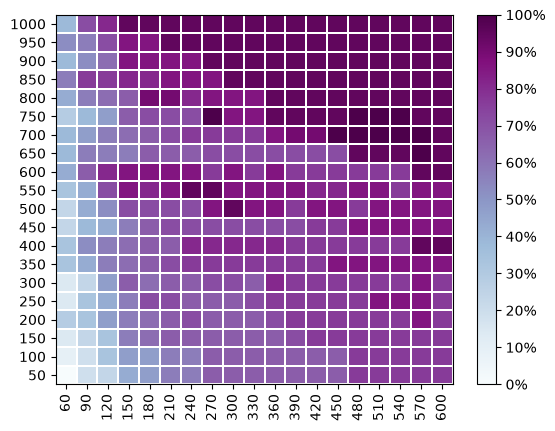

In [ ]:
 #| label: colourmesh

def my_colormesh(fig, ax, x, y, z):
    cmap = "BuPu"
    ax.pcolormesh(x, y, z, cmap=cmap, shading='nearest', edgecolors='white', linewidths=0.1)
    ax.tick_params('x', rotation=90)

    colorizer = mpl.colorizer.Colorizer(norm=mpl.colors.Normalize(0, 1), cmap=cmap)
    bar = fig.colorbar(mpl.colorizer.ColorizingArtist(colorizer),
                ax=ax, orientation='vertical')
    ticks = np.linspace(0, 1, 11)
    bar.set_ticks(ticks=ticks, labels=map(lambda x: f'{x:.0%}', ticks))

fig, ax = plt.subplots()
my_colormesh(fig, ax, lengths, offsets, z)
ax.set_xticks(lengths)
ax.set_yticks(offsets)
plt.show()

In [ ]:
# apply windows to data
# 30 minutes training, 10 minutes testing

# return the data, graph it seperately
def apply_windows(samples, offset, mode="idle", metrics=['mean']):
    data = get_data(mode)

    # just get the profiles as a list
    results = {device: compute_profile(training, samples, offset) for device, (training, _) in data.items()}
    # assign the pr
    matches = {}
    for device, (_, testing) in data.items():
        matches[device] = {}
        for metric in metrics:
            matches[device][metric] = []
            for point in compute_profile(testing, samples, offset)[metric]:
                # TODO fix the double computation here
                matches[device][metric].append(reduce(lambda old, new: new if abs(np.median(new[1][metric]) - point) < abs(np.median(old[1][metric]) - point) else old, results.items())[0])
    return matches

# https://en.wikipedia.org/wiki/Confusion_matrix#Confusion_matrices_in_multi-label_and_soft-label_classification
def confusion_matrix(devices_flat, matches, metric='mean', w=180):
    # convert the matches to a n x n matrix
    fig, ax = plt.subplots()
    n = len(devices_flat)
    matrix = np.zeros((n, n))
    for i, device in enumerate(devices_flat):
        windows = len(matches[device][metric])
        for name, count in Counter(matches[device][metric]).items():
            share = count / windows
        
            matrix[n - 1 - i][devices_flat.index(name)] = share
            

    scores = []

    for i in range(n):
        n = len(matrix)
        tp = matrix[n - 1 -i, i]
        fp = 0
        fn = 0
        for j in range(n):
            if j != i:
                fp += matrix[n - 1 - j][i]
                fn += matrix[n - 1 - i][j]
        scores.append(2 * tp / (2 * tp + fp + fn))

    my_colormesh(fig, ax, devices_flat[::-1] , [f'{device} {devices_to_cat[device]}' for i, device in enumerate(devices_flat)], matrix)

    for i in range(n):
        for j in range(n):
            share = matrix[n - i - 1][j]
            if share != 0:
                colour = 'black'
                if share > 0.1:
                    colour = 'white'      
                ax.text(n - i - 1, j, f'{share:.0%}', fontsize=3, ha='center',va='center', color=colour)
    # TODO are FPs scaled correcly
    # TODO there's an off by one error

    ax.tick_params('x', rotation=90)
    ax.set_ylabel("Real Class")
    ax.set_xlabel("Predicted Class")
    ax.set_title(f"Confusion Matrix:\n (state=idle, metric=mean, w = {w} s = 10) classified using median")
    # fig.set_figwidth(50)
    fig.set_dpi(200)

    return matrix



In [ ]:
data = apply_windows(180, 10)

In [ ]:
#| label: confusion

matrix = confusion_matrix(devices_flat, data)
plt.show()
# d = sort_dict_by_value({device: f1_score(matrix, i) for i, device in enumerate(devices_flat)}, reverse=True)
# d = {device: f1_score(matrix, i) for i, device in enumerate(local_dev[::-1])}
# df = pd.DataFrame({'devices': d.keys(), 'f1': d.values()})
                                   
# def my_style(styler):
#     styler.format("{:.2f}", 'f1')
#     return styler
# df.style.pipe(my_style)


NameError: name 'confusion_matrix' is not defined

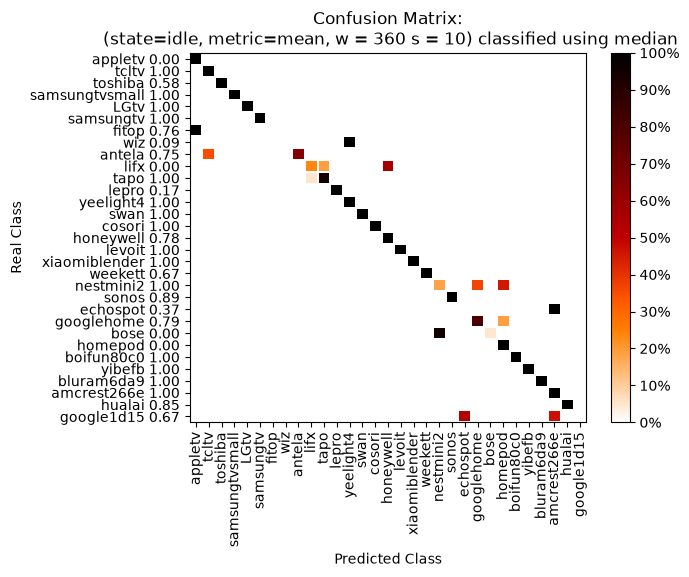

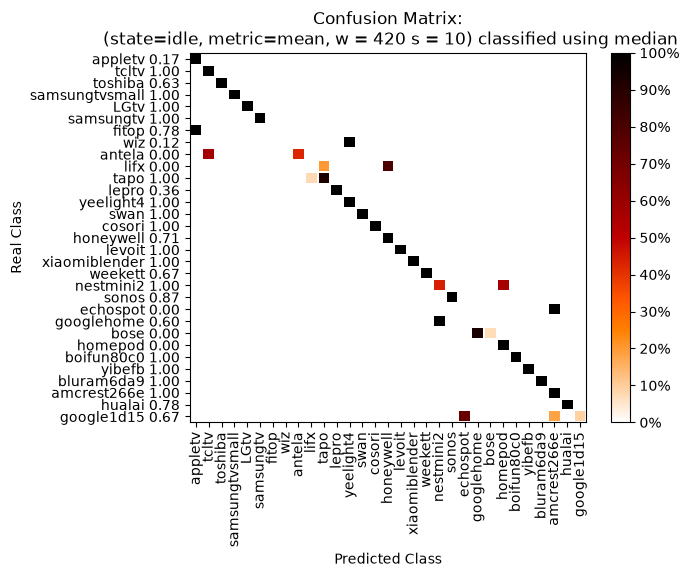

In [ ]:
#| label: confusion2
data = apply_windows(360, 10,)
matrix = confusion_matrix(local_dev, data, w=360)
data = apply_windows(420, 10,)
matrix = confusion_matrix(local_dev, data, w=420)


In [ ]:
"""
Find overlapping intervals, return the number of non-overlapping intervals and the total amount of overlap.

A faster algorithm would place all on same numberline, then it's like the brackets problem. n log n
Do naive n^2 algo for now.

For 2d overlaps, do both? Any overlap counts.

>>> overlap_intervals((pd.Interval(left=1, right=3), pd.Interval(left=2, right=4), pd.Interval(left=10, right=20)))
1
"""
def overlap_intervals(intervals, metrics=['mean']):
    # TODO: look at multiple metrics here
    for i in range(len(metrics)):
        pass
    # compare the two metrics for the same thing

    independents = 0
    for i, interval in enumerate(intervals):
        independent = True 
        for j, compare in enumerate(intervals):
            if i != j:
                if interval.overlaps(compare):
                    independent = False
        if independent:
            independents += 1

    return independents

import doctest
doctest.testmod(verbose=True)

Trying:
    overlap_intervals((pd.Interval(left=1, right=3), pd.Interval(left=2, right=4), pd.Interval(left=10, right=20)))
Expecting:
    1
ok
Trying:
    len(profile(pd.DataFrame(data={'power_mW': [1] * 100}), 10, 2)['mean'])
Expecting:
    46
ok
Trying:
    len(profile(pd.DataFrame(data={'power_mW': [1] * 101}), 10, 2)['mean'])
Expecting:
    46
ok
Trying:
    len(profile(pd.DataFrame(data={'power_mW': [1] * 100}), 10, 20)['mean'])
Expecting:
    5
ok
Trying:
    len(profile(pd.DataFrame(data={'power_mW': [1] * 1750}), 400, 10)['mean'])
Expecting:
    136
ok
12 items had no tests:
    __main__.State
    __main__.compute_overlap
    __main__.get_data
    __main__.get_dataframe
    __main__.graph_profiles
    __main__.intervalise
    __main__.my_style
    __main__.overlap
    __main__.overlap_intervals
    __main__.plot
    __main__.sort_dict_by_value
    __main__.window
2 items passed all tests:
   1 test in __main__
   4 tests in __main__.profile
5 tests in 14 items.
5 passed.
Test 

TestResults(failed=0, attempted=5)